# 4. LangGraph — State-Based Agent Workflows

## Overview

`create_agent()` is convenient but opaque: you get one loop, and you cannot change what
happens inside it. **LangGraph** is the layer underneath. You define the workflow as a
**graph** — nodes that do work, edges that decide what runs next, and a **state** object that
every node reads and writes.

This notebook covers four things:

1. **State-based workflows** — how state, nodes and edges fit together
2. **Stateful multi-step agents** — a tool-calling agent built from scratch
3. **Conditional edges and branching logic** — routing, loops, and parallel fan-out
4. **Debugging and visualising graphs** — seeing the structure, streaming steps, and time travel

This is the most important notebook in the lab for healthcare work, and the reason is section 4.
Up to now, "do not give clinical advice" has been a sentence in a prompt — advice the model
usually follows. Here you make it **structure**: a routing node that inspects every incoming
message and sends clinical content down a different path entirely. A guardrail you can draw as a
diagram is a guardrail you can show an auditor.


## Concepts

| Concept | Meaning |
|---|---|
| **State** | A typed dictionary passed through the graph. The single source of truth |
| **Node** | A Python function: `state -> partial state update` |
| **Edge** | A fixed transition: after node A, always run node B |
| **Conditional edge** | A function that inspects state and *chooses* the next node |
| **Reducer** | How updates to a state key combine (replace by default, or append) |
| **`START` / `END`** | The graph's entry and exit points |
| **Checkpointer** | Saves state after every node, enabling memory, resume, and time travel |


#### 0. Setup

In [1]:
# ---------------------------------------------------------------------------
# SageMaker Studio setup
#
# There is no .env file and no access key in this lab. boto3 automatically
# picks up short-lived credentials from the SageMaker execution role attached
# to this space, which is both simpler and safer than a long-lived key pair.
# ---------------------------------------------------------------------------
import os
import boto3

# Leave this as None to use the region this SageMaker space is running in.
# Set it ONLY if you enabled Bedrock model access in a different region.
BEDROCK_REGION = None

AWS_REGION = BEDROCK_REGION or boto3.session.Session().region_name or "us-east-1"
CHAT_MODEL_ID = os.environ.get("BEDROCK_CHAT_MODEL_ID", "amazon.nova-pro-v1:0")

from langchain_aws import ChatBedrockConverse

session = boto3.Session(region_name=AWS_REGION)

# Show which IAM identity this notebook is using. On SageMaker this is the
# execution role of your space - the role that needs Bedrock permissions.
identity = session.client("sts").get_caller_identity()
EXECUTION_ROLE_ARN = identity["Arn"]

model = ChatBedrockConverse(
    model=CHAT_MODEL_ID,
    client=session.client("bedrock-runtime"),
    temperature=0,
    max_tokens=1024,
)

print("Region         :", AWS_REGION)
print("Execution role :", EXECUTION_ROLE_ARN)
print("Connected to   :", CHAT_MODEL_ID)

Region         : us-east-1
Execution role : arn:aws:sts::442042521384:assumed-role/AmazonSageMaker-ExecutionRole-20260807T102279/SageMaker
Connected to   : amazon.nova-pro-v1:0


> **Sample data only.** Every claim, member and denial in this notebook is invented for
> training. Nothing here is a real coverage determination.

---
## 1. Your first graph

Three steps, always in the same order. The task is a real one from member communications:
turn a dense denial notice into something a member can actually understand and act on.

```
START -> draft -> critique -> improve -> END
```

#### 1.1. Define the state

In [2]:
from typing import TypedDict


class NoticeState(TypedDict):
    source_notice: str
    draft: str
    critique: str
    final: str

Every node receives the whole state and returns **only the keys it changed**.
LangGraph merges the update in for you.

#### 1.2. Define the nodes

In [3]:
def draft_node(state: NoticeState) -> dict:
    prompt = (
        "Rewrite this health plan notice so a member with no insurance background can "
        "understand it. Keep every fact, deadline and dollar amount exactly as written. "
        "Do not add clinical advice. Maximum 120 words.\n\n"
        f"{state['source_notice']}"
    )
    return {"draft": model.invoke(prompt).content}


def critique_node(state: NoticeState) -> dict:
    prompt = (
        "You review member communications for a health plan. List exactly 3 specific "
        "weaknesses in this rewrite. Check especially for: a dropped deadline, a dropped "
        "dollar amount, jargon left untranslated, or any implied clinical advice.\n\n"
        f"{state['draft']}"
    )
    return {"critique": model.invoke(prompt).content}


def improve_node(state: NoticeState) -> dict:
    prompt = (
        "Rewrite this member notice addressing every critique. Keep it under 120 words.\n\n"
        f"NOTICE:\n{state['draft']}\n\nCRITIQUE:\n{state['critique']}\n\n"
        "Return only the improved notice."
    )
    return {"final": model.invoke(prompt).content}

#### 1.3. Wire the graph and compile it

In [4]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(NoticeState)

builder.add_node("draft", draft_node)
builder.add_node("critique", critique_node)
builder.add_node("improve", improve_node)

builder.add_edge(START, "draft")
builder.add_edge("draft", "critique")
builder.add_edge("critique", "improve")
builder.add_edge("improve", END)

notice_graph = builder.compile()
print("Graph compiled")

Graph compiled


In [5]:
DENIAL_NOTICE = (
    "Claim 88213-04 for CPT 70553 (MRI brain w/wo contrast, DOS 03/02) has been adjudicated as "
    "DENIED, reason code CO-197: precertification/authorisation absent. Member liability is "
    "determined at $1,842.00 pending provider adjustment. A request for redetermination may be "
    "submitted within 60 calendar days of the date of this notice."
)

result = notice_graph.invoke({"source_notice": DENIAL_NOTICE})

print("--- DRAFT ---\n", result["draft"])
print("\n--- CRITIQUE ---\n", result["critique"])
print("\n--- FINAL ---\n", result["final"])

--- DRAFT ---
 Your MRI brain scan claim (88213-04) from 03/02 was denied because precertification was missing. You owe $1,842.00 until the provider adjusts the claim. You can ask us to review this decision within 60 days of this notice.

--- CRITIQUE ---
 Here are three specific weaknesses in the provided rewrite:

1. **Dropped Dollar Amount in the Call to Action**: The original sentence includes a specific dollar amount ($1,842.00) that the member owes, but this amount is not repeated in the call to action. It would be clearer to remind the member of the exact amount they owe when instructing them on what to do next.

2. **Jargon Left Untranslated**: The term "precertification" is used without explanation. For many members, this term may not be clear. It would be better to either define the term or use simpler language, such as "prior approval."

3. **Implied Clinical Advice**: The sentence implies that the member can ask for a review "within 60 days of this notice," which could be i

---
## 2. Visualising the graph

A compiled graph can describe itself. Three ways, in order of how reliably they work offline.

#### 2.1. Mermaid text — always works

In [6]:
print(notice_graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	draft(draft)
	critique(critique)
	improve(improve)
	__end__([<p>__end__</p>]):::last
	__start__ --> draft;
	critique --> improve;
	draft --> critique;
	improve --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



Paste that into <https://mermaid.live> for a rendered diagram, or into any Markdown
file that supports Mermaid.

> Keep these diagrams. When a compliance or clinical governance reviewer asks how an automated
> member communication is produced, a graph diagram answers the question in a way that a prompt
> and a stack trace do not.

#### 2.2. ASCII — works offline, needs the `grandalf` package

In [7]:
try:
    print(notice_graph.get_graph().draw_ascii())
except Exception as e:
    print("ASCII rendering unavailable:", e)
    print("Install it with: pip install grandalf")

+-----------+  
| __start__ |  
+-----------+  
      *        
      *        
      *        
  +-------+    
  | draft |    
  +-------+    
      *        
      *        
      *        
+----------+   
| critique |   
+----------+   
      *        
      *        
      *        
 +---------+   
 | improve |   
 +---------+   
      *        
      *        
      *        
 +---------+   
 | __end__ |   
 +---------+   


#### 2.3. PNG — prettiest, requires internet access

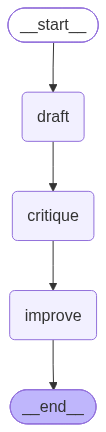

In [8]:
from IPython.display import Image, display

try:
    display(Image(notice_graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("PNG rendering unavailable (needs internet):", e)

---
## 3. Stateful multi-step agents

Now we build a tool-calling agent by hand — the same loop `create_agent()` gives you, except
you can see and change every part of it.

```
                +-----------+
   START -----> |   model   | <----------+
                +-----------+            |
                      |                  |
              (tool calls?)              |
                 /        \             |
              yes          no            |
               |            |            |
          +---------+       v            |
          |  tools  | ------------------+
          +---------+      END
```

The loop keeps running until the model answers without requesting a tool.

#### 3.1. Message state and the `add_messages` reducer

In [9]:
from typing import Annotated
from langgraph.graph.message import add_messages


class AgentState(TypedDict):
    messages: Annotated[list, add_messages]

That `Annotated[..., add_messages]` is the important line. Without a reducer, every
node returning `messages` would **overwrite** the conversation. `add_messages` **appends**
instead — which is exactly what a conversation needs.

#### 3.2. Tools

In [10]:
from langchain_core.tools import tool


@tool
def estimate_member_cost(billed_amount: float, deductible_remaining: float,
                         coinsurance_pct: float = 20.0) -> str:
    """Estimate what a member owes for a service under a standard deductible-plus-coinsurance plan.

    billed_amount is the allowed amount for the service in USD.
    deductible_remaining is how much of the member's annual deductible is still unmet.
    coinsurance_pct is the member's share after the deductible, as a percentage.

    The member pays the deductible portion in full, then the coinsurance percentage of
    whatever is left. This returns a sample estimate, not a coverage determination.
    """
    to_deductible = min(billed_amount, max(deductible_remaining, 0))
    after_deductible = billed_amount - to_deductible
    coinsurance = round(after_deductible * coinsurance_pct / 100, 2)
    total = round(to_deductible + coinsurance, 2)
    return (
        f"Allowed amount ${billed_amount}. "
        f"${to_deductible} applied to the remaining deductible, "
        f"${after_deductible} subject to {coinsurance_pct}% coinsurance = ${coinsurance}. "
        f"Estimated member responsibility: ${total}."
    )


@tool
def check_prior_auth_required(service: str) -> str:
    """Check whether a service requires prior authorisation under the sample plan.

    Valid services include: mri, ct_scan, pet_scan, inpatient_admission, outpatient_surgery,
    physical_therapy, durable_medical_equipment, primary_care_visit, lab_work.
    """
    rules = {
        "mri": "Prior authorisation REQUIRED for outpatient MRI",
        "ct_scan": "Prior authorisation REQUIRED for outpatient CT",
        "pet_scan": "Prior authorisation REQUIRED",
        "inpatient_admission": "Prior authorisation REQUIRED except emergency admissions",
        "outpatient_surgery": "Prior authorisation REQUIRED for selected procedures",
        "physical_therapy": "Not required for the first 12 visits, then REQUIRED",
        "durable_medical_equipment": "REQUIRED for items over $500",
        "primary_care_visit": "Not required",
        "lab_work": "Not required for in-network labs",
    }
    key = service.lower().strip().replace(" ", "_")
    return rules.get(key, f"No prior authorisation rule on file for '{service}'.")


tools = [estimate_member_cost, check_prior_auth_required]
model_with_tools = model.bind_tools(tools)
print("Tools bound:", [t.name for t in tools])

Tools bound: ['estimate_member_cost', 'check_prior_auth_required']


#### 3.3. Nodes

In [11]:
from langgraph.prebuilt import ToolNode

def call_model(state: AgentState) -> dict:
    response = model_with_tools.invoke(state["messages"])
    return {"messages": [response]}


tool_node = ToolNode(tools)

`ToolNode` is a prebuilt node that reads the `tool_calls` off the last message, runs
the matching tools, and appends `ToolMessage` results. Writing it yourself is about fifteen
lines — this saves you from the error handling.

#### 3.4. The conditional edge that creates the loop

In [12]:
from typing import Literal


def should_continue(state: AgentState) -> Literal["tools", "__end__"]:
    """Route to the tool node if the model asked for a tool, otherwise finish."""
    last_message = state["messages"][-1]
    if getattr(last_message, "tool_calls", None):
        return "tools"
    return "__end__"

In [13]:
agent_builder = StateGraph(AgentState)

agent_builder.add_node("model", call_model)
agent_builder.add_node("tools", tool_node)

agent_builder.add_edge(START, "model")
agent_builder.add_conditional_edges("model", should_continue, {"tools": "tools", "__end__": END})
agent_builder.add_edge("tools", "model")   # <-- this edge is what makes it a loop

custom_agent = agent_builder.compile()
print(custom_agent.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools)
	__end__([<p>__end__</p>]):::last
	__start__ --> model;
	model -.-> __end__;
	model -.-> tools;
	tools --> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [14]:
out = custom_agent.invoke({"messages": [
    {"role": "user", "content":
     "Does an outpatient MRI need prior authorisation, and if the allowed amount is $1,842 "
     "with $400 of my deductible left, what do I owe?"}
]})

for m in out["messages"]:
    m.pretty_print()

================================ Human Message =================================

Does an outpatient MRI need prior authorisation, and if the allowed amount is $1,842 with $400 of my deductible left, what do I owe?
================================== Ai Message ==================================

[{'type': 'reasoning_content', 'reasoning_content': {'text': "First, I need to check if an outpatient MRI requires prior authorization. Then, I will calculate the member's cost based on the allowed amount and the remaining deductible."}}, {'type': 'tool_use', 'name': 'check_prior_auth_required', 'input': {'service': 'mri'}, 'id': 'tooluse_bf2d75OlDWGn2og2xCG8nI'}, {'type': 'tool_use', 'name': 'estimate_member_cost', 'input': {'deductible_remaining': 400, 'billed_amount': 1842}, 'id': 'tooluse_GUAMttkfBGWGl5klJrCeNH'}]
Tool Calls:
  check_prior_auth_required (tooluse_bf2d75OlDWGn2og2xCG8nI)
 Call ID: tooluse_bf2d75OlDWGn2og2xCG8nI
  Args:
    service: mri
  estimate_member_cost (tooluse_GUAMttkf

---
## 4. Conditional edges and branching logic

The loop above is one use of conditional edges. The other big one is **routing**: send the
work to a different specialist depending on what it is.

This is where the scope guardrail stops being a suggestion. Every incoming member message is
classified first, and clinical content is routed to a node that **cannot** answer it — it only
produces an escalation. The model is not trusted to decline; the graph does not give it the
option.

```
                        +-> claims_node -----+
                        |                    |
                        +-> coverage_node ---+
START -> classify ------+                    +-> respond -> END
                        +-> enrolment_node --+
                        |                    |
                        +-> clinical_node ---+   (escalate, never answer)
```

#### 4.1. State and classifier

In [15]:
class InquiryState(TypedDict):
    inquiry: str
    category: str
    internal_notes: str
    escalate: bool
    reply: str


VALID_CATEGORIES = {"claims", "coverage", "enrolment", "clinical"}


def classify(state: InquiryState) -> dict:
    prompt = (
        "Classify this member message into exactly one word:\n"
        "claims    - a specific claim, bill, denial, payment or appeal\n"
        "coverage  - whether something is covered, and what the member pays\n"
        "enrolment - signing up, changing plans, premiums, enrolment periods\n"
        "clinical  - symptoms, diagnosis, treatment choice, medication, or whether the "
        "member should have a procedure\n\n"
        "If the message contains ANY clinical element, answer clinical.\n\n"
        f"Message: {state['inquiry']}\n\nAnswer with one word only."
    )
    category = model.invoke(prompt).content.strip().lower()
    if category not in VALID_CATEGORIES:
        category = "coverage"
    print(f"[classify] -> {category}")
    return {"category": category}

> **Note the tie-break rule.** "If the message contains ANY clinical element, answer clinical."
> A mixed message routes to the safe branch, not the convenient one. You will lose some
> answerable benefits questions to escalation — that is the correct trade in this domain, and it
> is a decision you should make deliberately rather than discover in production.

#### 4.2. The four branches

In [16]:
def claims_branch(state: InquiryState) -> dict:
    prompt = (
        "You are a claims specialist at a health plan. For this member message, note the key "
        "claim facts, the likely denial or payment reason, and the next actions including any "
        f"appeal deadline:\n{state['inquiry']}"
    )
    return {"internal_notes": model.invoke(prompt).content, "escalate": False}


def coverage_branch(state: InquiryState) -> dict:
    prompt = (
        "You are a benefits specialist. Summarise what general Medicare rules say about this "
        "question, and flag what depends on the member's specific plan. No clinical advice:\n"
        f"{state['inquiry']}"
    )
    return {"internal_notes": model.invoke(prompt).content, "escalate": False}


def enrolment_branch(state: InquiryState) -> dict:
    prompt = (
        "You are an enrolment specialist. Note the relevant enrolment period, any deadline, "
        f"and any penalty risk for this member message:\n{state['inquiry']}"
    )
    return {"internal_notes": model.invoke(prompt).content, "escalate": False}


def clinical_branch(state: InquiryState) -> dict:
    """No model call at all. This branch cannot answer, by construction."""
    return {
        "internal_notes": (
            "CLINICAL CONTENT DETECTED. This assistant is not permitted to respond to "
            "clinical questions. Route to the nurse line and log for review."
        ),
        "escalate": True,
    }


def respond(state: InquiryState) -> dict:
    if state["escalate"]:
        return {"reply": (
            "Thanks for reaching out. Part of your message is a medical question, and I'm not "
            "able to help with those. Please speak with your doctor, or call the 24-hour nurse "
            "line on the back of your member ID card. If you also have a question about "
            "coverage, billing or enrolment, reply with just that part and I'll help right away."
        )}
    prompt = (
        "Write a short, warm reply to this member. Plain language, no jargon, no clinical "
        "advice. State any deadline explicitly. End by noting their specific plan may differ."
        f"\n\nMessage: {state['inquiry']}\n"
        f"Category: {state['category']}\n"
        f"Internal notes: {state['internal_notes']}"
    )
    return {"reply": model.invoke(prompt).content}

> **Why `clinical_branch` makes no model call.** The safest node is one that has no opportunity
> to improvise. There is no prompt to jailbreak and no temperature setting that changes the
> outcome — it returns a fixed escalation every time. When a guardrail matters, prefer the
> branch that cannot fail over the branch that usually succeeds.

#### 4.3. The routing function

A conditional edge function returns the **name of the next node**. That is all it is — a
Python function that reads state and returns a string.

In [17]:
def route_inquiry(state: InquiryState) -> Literal["claims", "coverage", "enrolment", "clinical"]:
    return state["category"]


inquiry_builder = StateGraph(InquiryState)

inquiry_builder.add_node("classify", classify)
inquiry_builder.add_node("claims", claims_branch)
inquiry_builder.add_node("coverage", coverage_branch)
inquiry_builder.add_node("enrolment", enrolment_branch)
inquiry_builder.add_node("clinical", clinical_branch)
inquiry_builder.add_node("respond", respond)

inquiry_builder.add_edge(START, "classify")
inquiry_builder.add_conditional_edges(
    "classify",
    route_inquiry,
    {"claims": "claims", "coverage": "coverage",
     "enrolment": "enrolment", "clinical": "clinical"},
)

# All four branches converge on the same node
inquiry_builder.add_edge("claims", "respond")
inquiry_builder.add_edge("coverage", "respond")
inquiry_builder.add_edge("enrolment", "respond")
inquiry_builder.add_edge("clinical", "respond")
inquiry_builder.add_edge("respond", END)

inquiry_graph = inquiry_builder.compile()
print(inquiry_graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	classify(classify)
	claims(claims)
	coverage(coverage)
	enrolment(enrolment)
	clinical(clinical)
	respond(respond)
	__end__([<p>__end__</p>]):::last
	__start__ --> classify;
	claims --> respond;
	classify -.-> claims;
	classify -.-> clinical;
	classify -.-> coverage;
	classify -.-> enrolment;
	clinical --> respond;
	coverage --> respond;
	enrolment --> respond;
	respond --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [18]:
inquiries = [
    "My MRI claim was denied for no prior authorisation and I was billed $1,842. What now?",
    "Are hearing aids covered, and if not is there any plan that covers them?",
    "I turn 65 in April. When do I need to sign up so I don't get a penalty?",
    "My knee has been swollen for a week. Should I get an MRI or just rest it?",
]

for q in inquiries:
    print("=" * 70)
    print("MESSAGE:", q)
    result = inquiry_graph.invoke({"inquiry": q, "escalate": False})
    print("CATEGORY:", result["category"], "| ESCALATED:", result["escalate"])
    print("REPLY:", result["reply"][:320].strip())
    print()

MESSAGE: My MRI claim was denied for no prior authorisation and I was billed $1,842. What now?


[classify] -> coverage


CATEGORY: coverage | ESCALATED: False
REPLY: Hi there,

I'm sorry to hear about your MRI claim being denied and the bill you received. Here’s what you can do next:

1. **Review the Denial Notice**: Take a close look at the Medicare Summary Notice (MSN) or Explanation of Benefits (EOB) to understand why the claim was denied.

2. **File an Appeal**: 
   - You have

MESSAGE: Are hearing aids covered, and if not is there any plan that covers them?


[classify] -> coverage


CATEGORY: coverage | ESCALATED: False
REPLY: Hi there,

Thanks for your question about hearing aids. Under general Medicare rules, Original Medicare (Part A and Part B) doesn’t cover hearing aids. However, some Medicare Advantage (Part C) plans may offer coverage for them. These plans are offered by private insurance companies and can provide extra benefits.

If

MESSAGE: I turn 65 in April. When do I need to sign up so I don't get a penalty?


[classify] -> coverage


CATEGORY: coverage | ESCALATED: False
REPLY: Hi there,

Congratulations on turning 65 soon! To avoid any penalties, you'll want to sign up for Medicare Part B during your Initial Enrollment Period (IEP). Your IEP starts three months before you turn 65 and ends three months after. So, for you, it will run from January 1 to July 31.

If you miss this window for Par

MESSAGE: My knee has been swollen for a week. Should I get an MRI or just rest it?


[classify] -> clinical
CATEGORY: clinical | ESCALATED: True
REPLY: Thanks for reaching out. Part of your message is a medical question, and I'm not able to help with those. Please speak with your doctor, or call the 24-hour nurse line on the back of your member ID card. If you also have a question about coverage, billing or enrolment, reply with just that part and I'll help right away



The fourth message is the one to look at. It never reached a model that could answer it — the
classifier sent it to a branch with no model call, and the responder returned a fixed
escalation. That is a guardrail with a shape.

#### 4.4. Parallel branching (fan-out and fan-in)

Add two edges out of the same node and LangGraph runs both branches **concurrently**. When two
nodes write to the same state key at the same time you must give that key a reducer, or
LangGraph raises an `InvalidUpdateError`.

The example is a pre-submission review of an appeal package: one branch checks the coverage
argument, the other checks whether the documentation is complete. They are independent, so
running them in sequence would just be slower.

In [19]:
import operator


class AppealState(TypedDict):
    appeal_summary: str
    findings: Annotated[list, operator.add]   # reducer: concatenate lists
    verdict: str


def check_coverage_argument(state: AppealState) -> dict:
    out = model.invoke(
        "You review appeal packages for a health plan. Identify 2 weaknesses in the COVERAGE "
        "ARGUMENT of this appeal - the reasoning about why the service should be covered:\n"
        f"{state['appeal_summary']}"
    ).content
    return {"findings": [f"COVERAGE ARGUMENT:\n{out}"]}


def check_documentation(state: AppealState) -> dict:
    out = model.invoke(
        "You review appeal packages for a health plan. Identify 2 gaps in the DOCUMENTATION "
        "attached to this appeal - missing forms, dates, signatures or records:\n"
        f"{state['appeal_summary']}"
    ).content
    return {"findings": [f"DOCUMENTATION:\n{out}"]}


def combine(state: AppealState) -> dict:
    joined = "\n\n".join(state["findings"])
    out = model.invoke(
        "Give a one-paragraph submit / do-not-submit-yet verdict for this appeal package, "
        f"based on:\n\n{joined}"
    ).content
    return {"verdict": out}


parallel_builder = StateGraph(AppealState)
parallel_builder.add_node("coverage_argument", check_coverage_argument)
parallel_builder.add_node("documentation", check_documentation)
parallel_builder.add_node("combine", combine)

parallel_builder.add_edge(START, "coverage_argument")   # fan out
parallel_builder.add_edge(START, "documentation")       # fan out
parallel_builder.add_edge("coverage_argument", "combine")  # fan in
parallel_builder.add_edge("documentation", "combine")      # fan in
parallel_builder.add_edge("combine", END)

parallel_graph = parallel_builder.compile()
print(parallel_graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	coverage_argument(coverage_argument)
	documentation(documentation)
	combine(combine)
	__end__([<p>__end__</p>]):::last
	__start__ --> coverage_argument;
	__start__ --> documentation;
	coverage_argument --> combine;
	documentation --> combine;
	combine --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [20]:
appeal = (
    "Appeal for claim 88213-04, MRI brain denied CO-197 (no prior authorisation). "
    "Member states the ordering provider submitted the authorisation request by fax on 28 "
    "February but has no confirmation number. Attached: the denial notice and a letter from "
    "the member. Not attached: the provider's clinical notes, the fax transmission report, or "
    "a signed appointment of representative form. Denial notice is dated 12 March."
)

analysis = parallel_graph.invoke({"appeal_summary": appeal, "findings": []})

print("Findings collected:", len(analysis["findings"]))
print("\nVERDICT:\n", analysis["verdict"])

Findings collected: 2

VERDICT:
 **Verdict: Do Not Submit Yet**

Based on the identified weaknesses in both the coverage argument and the documentation, it is advisable not to submit this appeal package in its current state. The absence of critical documentation—specifically the provider's clinical notes, the fax transmission report, and the signed appointment of representative form—significantly undermines the coverage argument. These documents are essential for substantiating the medical necessity of the MRI, verifying that the prior authorization was requested, and confirming the legitimacy of the appeal submission. Without this evidence, the appeal is unlikely to be successful. It is recommended to obtain and include these missing documents before resubmitting the appeal to strengthen the case for coverage.


---
## 5. Debugging graphs

Three techniques, in the order you should reach for them.

#### 5.1. Stream updates — see each node fire

`stream_mode="updates"` yields only what each node changed. It is the fastest way to find the
node that produced the wrong value.

In [21]:
for step in inquiry_graph.stream(
    {"inquiry": "I was billed twice for the same office visit in March.", "escalate": False},
    stream_mode="updates",
):
    for node_name, update in step.items():
        print(f"NODE: {node_name}")
        for key, value in update.items():
            preview = str(value)[:120].replace("\n", " ")
            print(f"   {key} = {preview}")
        print()

[classify] -> claims
NODE: classify
   category = claims



NODE: claims
   internal_notes = Certainly! Here's a breakdown of the key claim facts, the likely denial or payment reason, and the next actions includin
   escalate = False



NODE: respond
   reply = Hi there,  Thanks for bringing this to our attention. It looks like you were billed twice for your office visit in March



#### 5.2. Inspect state history with a checkpointer

With a checkpointer attached, every node boundary is a saved snapshot you can read back.

In a regulated workflow this is the difference between "the system produced this reply" and
"here is every intermediate decision that led to this reply, in order". Only the second one
survives an audit.

In [22]:
try:
    from langgraph.checkpoint.memory import InMemorySaver as MemoryCheckpointer
except ImportError:
    from langgraph.checkpoint.memory import MemorySaver as MemoryCheckpointer

debug_graph = inquiry_builder.compile(checkpointer=MemoryCheckpointer())
config = {"configurable": {"thread_id": "debug-case-88213"}}

debug_graph.invoke(
    {"inquiry": "Why was my physical therapy visit 13 denied?", "escalate": False},
    config,
)

print("--- STATE HISTORY (newest first) ---")
for snapshot in debug_graph.get_state_history(config):
    print(f"next={snapshot.next}  keys_set={[k for k, v in snapshot.values.items() if v]}")

[classify] -> coverage


--- STATE HISTORY (newest first) ---
next=()  keys_set=['inquiry', 'category', 'internal_notes', 'reply']
next=('respond',)  keys_set=['inquiry', 'category', 'internal_notes']
next=('coverage',)  keys_set=['inquiry', 'category']
next=('classify',)  keys_set=['inquiry']
next=('__start__',)  keys_set=[]


#### 5.3. Time travel — replay from an earlier checkpoint

Each snapshot has a `checkpoint_id`. Pass one back in and the graph resumes from exactly that
point. This is how you re-run a single failing step without repeating the whole (expensive)
workflow.

It is also how you answer "would a different reply have been generated if the classifier had
routed this differently?" — a question that comes up in quality review far more often than you
would expect.

In [23]:
history = list(debug_graph.get_state_history(config))
print("Checkpoints available:", len(history))

# Pick the snapshot taken just before the 'respond' node ran
replay_point = None
for snapshot in history:
    if snapshot.next == ("respond",):
        replay_point = snapshot
        break

if replay_point is not None:
    print("Replaying from checkpoint:", replay_point.config["configurable"]["checkpoint_id"])
    replayed = debug_graph.invoke(None, replay_point.config)
    print("\nReplayed reply:\n", replayed["reply"][:300])
else:
    print("No matching checkpoint found - inspect `history` manually.")

Checkpoints available: 5
Replaying from checkpoint: 1f192287-4dbc-6f3b-8002-8c76efbdf132



Replayed reply:
 Hi there,

Thanks for reaching out. It looks like your physical therapy visit was denied, and I'm here to help clarify things.

Generally, Medicare Part B covers physical therapy if it's medically necessary and provided by a qualified therapist. However, there could be a few reasons for a denial, su


#### 5.4. Guard against runaway loops

An agent that keeps calling tools will loop forever. `recursion_limit` caps the number of
supersteps and raises `GraphRecursionError` instead of burning your Bedrock budget.

In [24]:
from langgraph.errors import GraphRecursionError

try:
    custom_agent.invoke(
        {"messages": [{"role": "user", "content":
                       "Check prior authorisation for every service type you know about."}]},
        {"recursion_limit": 4},
    )
except GraphRecursionError as e:
    print("Recursion limit hit as expected:", e)

#### 5.5. Debugging checklist

| Symptom | Where to look |
|---|---|
| A node never runs | The conditional edge mapping — does the returned string match a key? |
| State keeps getting overwritten | Missing reducer on that key (`Annotated[list, add_messages]`) |
| `InvalidUpdateError` on parallel branches | Two nodes write the same key without a reducer |
| Agent loops forever | Tool description is vague, so the model keeps re-calling. Also set `recursion_limit` |
| Works once, forgets next call | No checkpointer, or a different `thread_id` |
| Graph shape is not what you expected | `print(graph.get_graph().draw_mermaid())` before debugging logic |
| Clinical content reached a model | The classifier returned an unexpected string and fell through to the default. Log every classification and alert on the default path |

---
## Summary

- A LangGraph app is **state + nodes + edges**
- **Reducers** decide how state updates combine; `add_messages` appends, the default replaces
- **Conditional edges** give you loops (agent) and routing (branching)
- A guardrail expressed as a **routing node** is stronger than one expressed as a sentence
- The safest branch is one that makes no model call at all
- Fan-out and fan-in give you parallelism, and parallel writes need a reducer
- Debug with `stream_mode="updates"`, `get_state_history()`, time travel, and `recursion_limit`
- State history is your audit trail — in this domain, that is a requirement, not a nicety

**Next:** notebook `5-CrewAI-Multi-Agent.ipynb`, where instead of one agent with many tools we
use many agents with distinct roles.